# 02 — MAIN FINAL MODEL

| Item | Nilai |
|------|-------|
| **Model Terbaik** | XGBoost |
| **Feature Selection** | Mutual Information |
| **Skenario** | Full Data 80:20 (Holdout) |
| **Accuracy** | 0.8583 |
| **Precision** | 0.8126 |
| **Recall** | 0.8056 |
| **F1-Score** | 0.8090 |
| **MCC** | 0.6181 |
| **ROC-AUC** | 0.8967 |
| **Gap Accuracy** | 0.1396 |
| **Gap Macro F1** | 0.1882 |

**Alur:** EDA → Konfigurasi terbaik NB01 → HP Tuning via `GridSearchCV` (utils) → Evaluasi Holdout → SHAP


## 1. Setup & Import

In [1]:
# Import library dan fungsi bantu. 
# Di sini cuma perlu grid XGBoost karena model terbaik sudah ditentukan dari file 01.

import sys, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import VarianceThreshold, mutual_info_classif
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, f1_score

from utils import ( 
    fix_european, evaluate, diagnose_fit,
    make_feature_sets_split,
    tune_model, compute_shap,
    plot_shap_beeswarm, plot_shap_bar,
    TARGET, DROP,
    PARAM_GRID_XGB
)

print('Import selesai.')
print(f'XGB grid: {sum(len(v) for v in PARAM_GRID_XGB.values())} parameter total')


Import selesai.
XGB grid: 13 parameter total


## 2. Load & Persiapan Data

In [2]:
# Baca dataset training dan testing
df_train = pd.read_csv(
    'D:\Skripsi - DIAD\dataset\DIA_trainingset_RDKit_descriptors.csv',
    sep=','
)

df_test = pd.read_csv(
    'D:\Skripsi - DIAD\dataset\DIA_testset_RDKit_descriptors.csv',
    sep=','
)

# Lihat ukuran dan sebaran labelnya.
print('Train:', df_train.shape, '| Label:', dict(df_train['Label'].value_counts()))
print('Test :', df_test.shape, '| Label:', dict(df_test['Label'].value_counts()))

Train: (477, 198) | Label: {0: np.int64(359), 1: np.int64(118)}
Test : (120, 198) | Label: {0: np.int64(90), 1: np.int64(30)}


In [3]:
# Info tipe data
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 477 entries, 0 to 476
Columns: 198 entries, Label to fr_urea
dtypes: float64(83), int64(114), str(1)
memory usage: 763.3 KB


In [4]:
# Info missing values
df_train.isnull().sum()

Label               0
SMILES              0
BalabanJ            0
BertzCT             0
Chi0                0
                   ..
fr_thiazole         0
fr_thiocyan         0
fr_thiophene        0
fr_unbrch_alkane    0
fr_urea             0
Length: 198, dtype: int64

In [5]:
df_test.info()

<class 'pandas.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Columns: 198 entries, Label to fr_urea
dtypes: float64(83), int64(114), str(1)
memory usage: 192.7 KB


In [6]:
df_test.isnull().sum()

Label               0
SMILES              0
BalabanJ            0
BertzCT             0
Chi0                0
                   ..
fr_thiazole         0
fr_thiocyan         0
fr_thiophene        0
fr_unbrch_alkane    0
fr_urea             0
Length: 198, dtype: int64

In [7]:
# Statistik deskriptif
df_train.describe()

,Label,BalabanJ,BertzCT,Chi0,Chi0n,Chi0v,Chi1,Chi1n,Chi1v,Chi2n,...,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea
count,477.000000,477.000000,477.000000,477.000000,477.000000,477.000000,477.000000,477.000000,477.000000,477.000000,...,477.000000,477.000000,477.000000,477.000000,477.000000,477.000000,477.0,477.000000,477.000000,477.000000
mean,0.247379,2.142618,738.629776,18.130015,14.372379,14.886985,11.874170,8.433990,8.963610,6.672302,...,0.054507,0.050314,0.014675,0.006289,0.008386,0.031447,0.0,0.027254,0.327044,0.027254
std,0.431942,0.710916,392.967592,7.247300,6.093945,6.134658,4.828675,3.756045,3.813948,3.282600,...,0.245047,0.245944,0.120375,0.079138,0.091285,0.186342,0.0,0.175409,1.372740,0.162993
min,0.000000,0.986000,8.000000,3.414000,1.725000,1.725000,1.732000,0.612000,0.612000,0.250000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
25%,0.000000,1.679000,493.255000,13.405000,10.391000,10.763000,8.724000,5.807000,6.340000,4.399000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
50%,0.000000,1.964000,712.423000,17.646000,14.184000,14.683000,11.770000,8.351000,8.997000,6.362000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
75%,0.000000,2.419000,943.190000,22.052000,17.730000,18.216000,14.507000,10.588000,11.128000,8.554000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
max,1.000000,5.083000,2430.934000,50.120000,38.475000,39.837000,31.516000,23.166000,24.440000,19.352000,...,2.000000,2.000000,1.000000,1.000000,1.000000,2.000000,0.0,2.000000,18.000000,1.000000


In [8]:
# Statistik deskriptif
df_test.describe()

,Label,BalabanJ,BertzCT,Chi0,Chi0n,Chi0v,Chi1,Chi1n,Chi1v,Chi2n,...,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea
count,120.000000,120.000000,120.000000,120.000000,120.000000,120.000000,120.000000,120.000000,120.000000,120.000000,...,120.000000,120.000000,120.000000,120.000000,120.00000,120.000000,120.0,120.000000,120.000000,120.000000
mean,0.250000,2.145058,805.967508,19.685075,15.659142,16.107367,12.853417,9.127392,9.525583,7.308517,...,0.075000,0.008333,0.008333,0.016667,0.02500,0.008333,0.0,0.033333,0.358333,0.016667
std,0.434828,0.778106,443.927519,7.660753,6.308209,6.407406,5.096673,3.834029,3.917699,3.441829,...,0.294558,0.091287,0.091287,0.128556,0.15678,0.091287,0.0,0.222035,1.268863,0.128556
min,0.000000,0.837000,2.000000,2.000000,0.908000,0.908000,1.000000,0.204000,0.204000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.0,0.000000,0.000000,0.000000
25%,0.000000,1.675500,556.210750,15.267000,12.633750,12.853000,10.237000,7.363000,7.685750,5.608250,...,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.0,0.000000,0.000000,0.000000
50%,0.000000,1.946000,740.543500,18.629500,15.223500,15.568000,12.194500,8.814000,9.257500,7.084500,...,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.0,0.000000,0.000000,0.000000
75%,0.250000,2.353750,985.427000,23.656750,18.120000,18.533500,14.867000,10.832750,11.087750,8.987000,...,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.0,0.000000,0.000000,0.000000
max,1.000000,5.079000,2629.395000,48.141000,41.328000,41.328000,32.350000,23.269000,23.269000,18.816000,...,2.000000,1.000000,1.000000,1.000000,1.00000,1.000000,0.0,2.000000,9.000000,1.000000


In [9]:
# Bersihkan format angka, gabung train+test jadi X_full, lalu split 80:20.
# NaN diisi 0 supaya aman buat VarianceThreshold, MI, dan Spearman.
# fs_8020 dibuat di sini biar bisa langsung dipakai di bagian EDA.

X_train = fix_european(df_train.drop(columns=DROP))
y_train = df_train[TARGET].reset_index(drop=True)

X_test  = fix_european(df_test.drop(columns=DROP))
y_test  = df_test[TARGET].reset_index(drop=True)

# Gabungkan jadi X_full & y_full
X_full = pd.concat([X_train, X_test], ignore_index=True)
y_full = pd.concat([y_train, y_test], ignore_index=True)

# Split 80:20 dari X_full
Xtr80, Xte80, ytr80, yte80 = train_test_split(
    X_full, y_full, test_size=0.20, random_state=42, stratify=y_full)

ytr80_r = ytr80.reset_index(drop=True)
yte80_r = yte80.reset_index(drop=True)

# fillna(0) — mencegah error di VarianceThreshold, MI, Spearman
Xtr80  = Xtr80.fillna(0).reset_index(drop=True)
Xte80  = Xte80.fillna(0).reset_index(drop=True)
X_full = X_full.fillna(0)

# Buat fs_8020 di sini agar tersedia untuk EDA (Section 3)
fs_8020 = make_feature_sets_split(Xtr80, Xte80, ytr80_r)

# Copy untuk EDA
X_eda    = X_train.copy()
y_eda    = y_train.copy()
X_eda_te = X_test.copy()
y_eda_te = y_test.copy()
X_eda_sc = pd.DataFrame(
    StandardScaler().fit_transform(X_eda),
    columns=X_eda.columns
)

print(f'Full: {X_full.shape} | Xtr80: {Xtr80.shape} | Xte80: {Xte80.shape}')
print(f'fs_8020 siap. Keys: {list(fs_8020.keys())}')


Full: (597, 196) | Xtr80: (477, 196) | Xte80: (120, 196)
fs_8020 siap. Keys: ['Baseline', 'Variance Threshold', 'Zero Dominant', 'Spearman', 'Mutual Information']


In [10]:
# total NaN setelah fix_european
print(X_full.isnull().sum().sum())

0


## 3. EDA

### a) Distribusi Kelas

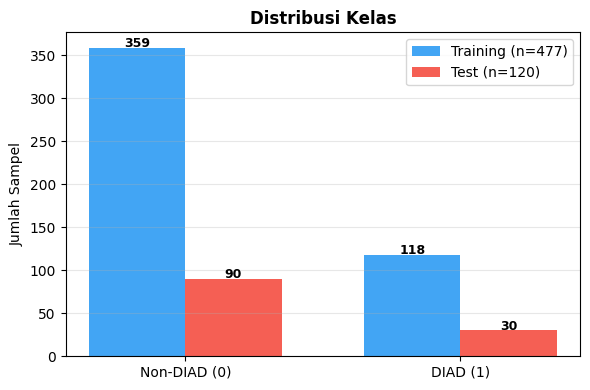

Rasio Train 0:1 = 3.04:1 | Rasio Test 0:1 = 3.00:1


In [11]:
c_tr = [(y_eda==0).sum(), (y_eda==1).sum()]
c_te = [(y_eda_te==0).sum(), (y_eda_te==1).sum()]
x_, w = np.arange(2), 0.35

fig, ax = plt.subplots(figsize=(6, 4))
b1 = ax.bar(x_-w/2, c_tr, w, label=f'Training (n={len(y_eda)})',  color='#2196F3', alpha=0.85)
b2 = ax.bar(x_+w/2, c_te, w, label=f'Test (n={len(y_eda_te)})',   color='#F44336', alpha=0.85)
for b in list(b1)+list(b2):
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+1,
            str(int(b.get_height())), ha='center', fontsize=9, fontweight='bold')
ax.set_xticks(x_); ax.set_xticklabels(['Non-DIAD (0)', 'DIAD (1)'])
ax.set_title('Distribusi Kelas', fontweight='bold')
ax.set_ylabel('Jumlah Sampel'); ax.legend(); ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()
print(f'Rasio Train 0:1 = {c_tr[0]/c_tr[1]:.2f}:1 | Rasio Test 0:1 = {c_te[0]/c_te[1]:.2f}:1')

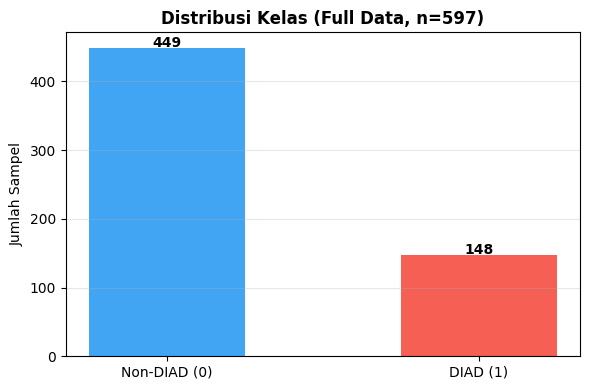

Non-DIAD : 449 (75.21%)
DIAD     : 148 (24.79%)
Rasio 0:1 = 3.03:1


In [12]:

# Distribusi kelas pada data gabungan (y_full)

c_full = [(y_full == 0).sum(), (y_full == 1).sum()]
x_ = np.arange(2)

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(x_, c_full, 0.5, color=['#2196F3', '#F44336'], alpha=0.85)
for b in bars:
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 1,
            str(int(b.get_height())), ha='center', fontsize=10, fontweight='bold')
ax.set_xticks(x_); ax.set_xticklabels(['Non-DIAD (0)', 'DIAD (1)'])
ax.set_title(f'Distribusi Kelas (Full Data, n={len(y_full)})', fontweight='bold')
ax.set_ylabel('Jumlah Sampel'); ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()

total = len(y_full)
print(f'Non-DIAD : {c_full[0]} ({c_full[0]/total*100:.2f}%)')
print(f'DIAD     : {c_full[1]} ({c_full[1]/total*100:.2f}%)')
print(f'Rasio 0:1 = {c_full[0]/c_full[1]:.2f}:1')

### b) Tipe Fitur & Jumlah Fitur per Metode FS

Varians Fitur

Fitur varians rendah (< 0.01) : 29
Fitur varians normal (≥ 0.01) : 167

── Daftar fitur varians rendah (< 0.01) ──
                        Variance
NumRadicalElectrons     0.000000
VSA_EState1             0.000000
VSA_EState2             0.000000
VSA_EState7             0.000000
VSA_EState6             0.000000
VSA_EState5             0.000000
VSA_EState4             0.000000
VSA_EState3             0.000000
SlogP_VSA9              0.000000
SMR_VSA8                0.000000
fr_prisulfonamd         0.000000
fr_isothiocyan          0.000000
fr_isocyan              0.000000
fr_diazo                0.000000
fr_barbitur             0.000000
fr_azide                0.000000
fr_thiocyan             0.000000
fr_oxazole              0.001675
fr_azo                  0.001675
fr_hdrzone              0.003344
fr_C_S                  0.003344
fr_nitroso              0.003344
fr_SH                   0.008319
fr_term_acetylene       0.008319
fr_oxime                0.008319
MaxAbsPartialCharge     0.0

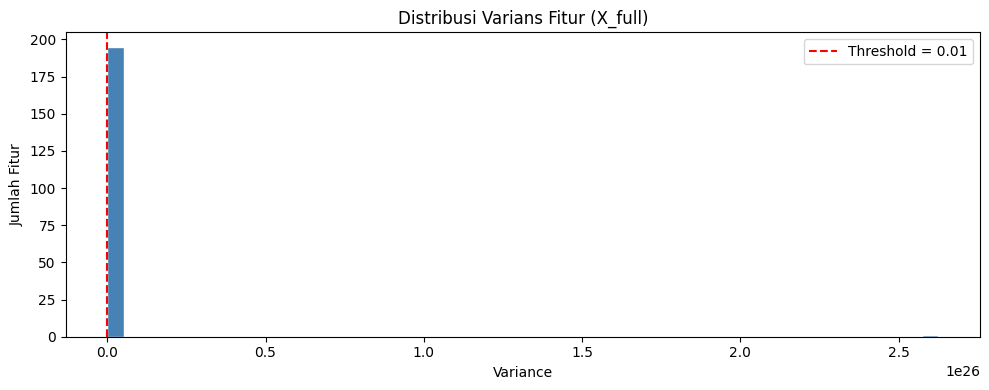

In [13]:
variances = X_full.var().sort_values()
low_var   = variances[variances < 0.01]
high_var  = variances[variances >= 0.01]

print(f"Fitur varians rendah (< 0.01) : {len(low_var)}")
print(f"Fitur varians normal (≥ 0.01) : {len(high_var)}")

print(f"\n── Daftar fitur varians rendah (< 0.01) ──")
print(low_var.to_frame(name='Variance').to_string())

print(f"\n── Daftar fitur varians tertinggi ──")
print(variances.sort_values(ascending=False).to_frame(name='Variance').to_string())

with pd.option_context('display.max_rows', None, 'display.float_format', '{:.6e}'.format):
    print(f"\n── Daftar semua fitur (varians terkecil → terbesar) ──")
    print(variances.to_frame(name='Variance').to_string())

plt.figure(figsize=(10, 4))
plt.hist(variances, bins=50, color='steelblue', edgecolor='white')
plt.axvline(0.01, color='red', linestyle='--', label='Threshold = 0.01')
plt.title("Distribusi Varians Fitur (X_full)")
plt.xlabel("Variance")
plt.ylabel("Jumlah Fitur")
plt.legend()
plt.tight_layout()
plt.show()

In [14]:
print(variances.sort_values(ascending=False).head(5))
# fitur nomor dua (BertzCT) variansnya "cuma" 163 ribu. Tapi Ipc = 10²⁶ — itu 21 digit lebih besar dari BertzCT. 
# Ipc sendirian yang meregangkan sumbu X sampai 10²⁶ di grafik ini. 
# Semua fitur lain, bahkan yang variansnya puluhan ribu, jadi tampak "nol" di sebelahnya.

Ipc               2.625548e+26
BertzCT           1.634092e+05
MolWt             2.209505e+04
ExactMolWt        2.205678e+04
HeavyAtomMolWt    1.941447e+04
dtype: float64


Ipc = Information Content of the Coefficients of the characteristic polynomial of the adjacency matrix.

Deskriptor ini menghitung sesuatu yang tumbuh secara eksponensial mengikuti ukuran molekul. Untuk molekul besar, nilainya bisa meledak sampai jutaan-miliaran. RDKit sendiri sebenarnya menyediakan versi ternormalisasi (AvgIpc) justru karena Ipc versi mentah terkenal bikin masalah numerik seperti ini alias "memang sifat bawaan deskriptornya".

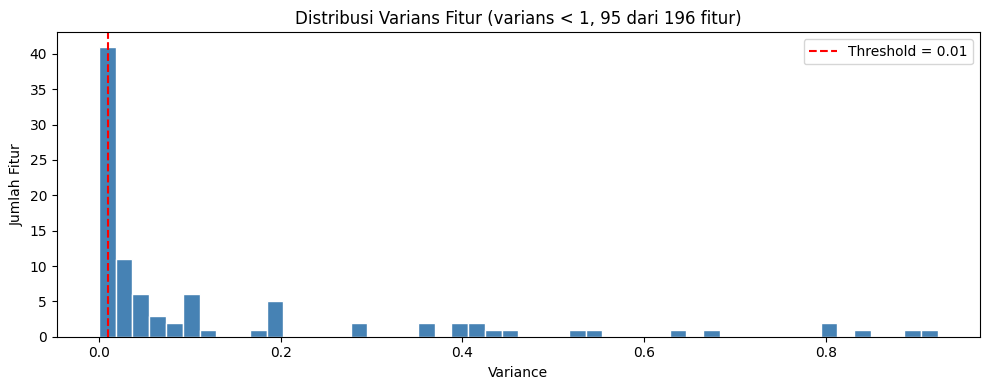

Fitur ditampilkan (varians < 1)   : 95
Fitur disembunyikan (varians ≥ 1) : 101  <- termasuk Ipc, BertzCT, MolWt, dll
Fitur di bawah threshold 0,01     : 29  <- ini yang dieliminasi Variance Threshold


In [15]:
# ── Penjelasan ──
# Histogram varians difokuskan ke fitur bervarians < 1 supaya threshold 0,01
# terlihat jelas. Fitur bervarians ekstrem (Ipc, BertzCT, MolWt, dll) sengaja
# tidak digambar agar terbaca — jumlahnya tetap dilaporkan lewat print.

mask = variances < 1
plt.figure(figsize=(10, 4))
plt.hist(variances[mask], bins=50, color='steelblue', edgecolor='white')
plt.axvline(0.01, color='red', linestyle='--', label='Threshold = 0.01')
plt.title(f"Distribusi Varians Fitur (varians < 1, {mask.sum()} dari {len(variances)} fitur)")
plt.xlabel("Variance")
plt.ylabel("Jumlah Fitur")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Fitur ditampilkan (varians < 1)   : {mask.sum()}")
print(f"Fitur disembunyikan (varians ≥ 1) : {(~mask).sum()}  <- termasuk Ipc, BertzCT, MolWt, dll")
print(f"Fitur di bawah threshold 0,01     : {(variances < 0.01).sum()}  <- ini yang dieliminasi Variance Threshold")

Zero Dominant Features

Fitur >80% bernilai NOL saja (cek zero)    : 84
Fitur >80% nilai DOMINAN (definisi ZDE)    : 84
Fitur normal (≤ 80% dominan)               : 112

── Daftar fitur ZDE (nilai dominan > 80%) dari X_full ──
                        Dominant_Pct
NumRadicalElectrons         1.000000
VSA_EState2                 1.000000
SlogP_VSA9                  1.000000
SMR_VSA8                    1.000000
VSA_EState7                 1.000000
VSA_EState4                 1.000000
VSA_EState6                 1.000000
VSA_EState1                 1.000000
VSA_EState3                 1.000000
VSA_EState5                 1.000000
fr_isocyan                  1.000000
fr_azide                    1.000000
fr_barbitur                 1.000000
fr_prisulfonamd             1.000000
fr_thiocyan                 1.000000
fr_isothiocyan              1.000000
fr_diazo                    1.000000
fr_azo                      0.998325
fr_oxazole                  0.998325
fr_nitroso                  0.996650
fr_C_S              

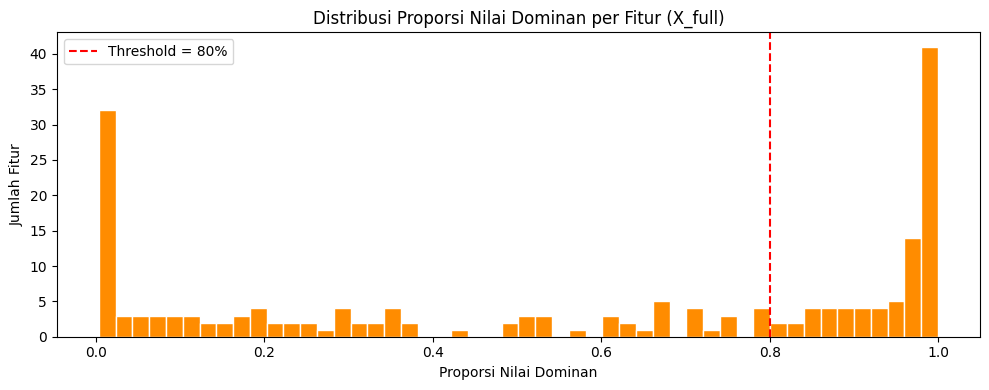

In [16]:
# ── ZERO-DOMINANT FEATURES (Eksplorasi X_full) ─────────────────────────

zero_pct_full = (X_full == 0).mean().sort_values(ascending=False)  # cek nol saja
zde_dom_full  = X_full.apply(lambda c: c.value_counts(normalize=True).max())  # nilai dominan

n_zero_only = int((zero_pct_full > 0.80).sum())
n_zde_full  = int((zde_dom_full > 0.80).sum())

print(f"Fitur >80% bernilai NOL saja (cek zero)    : {n_zero_only}")
print(f"Fitur >80% nilai DOMINAN (definisi ZDE)    : {n_zde_full}")
print(f"Fitur normal (≤ 80% dominan)               : {X_full.shape[1] - n_zde_full}")

zde_list_full = zde_dom_full[zde_dom_full > 0.80].sort_values(ascending=False)
print(f"\n── Daftar fitur ZDE (nilai dominan > 80%) dari X_full ──")
print(zde_list_full.to_frame(name='Dominant_Pct').to_string())

plt.figure(figsize=(10, 4))
plt.hist(zde_dom_full, bins=50, color='darkorange', edgecolor='white')
plt.axvline(0.80, color='red', linestyle='--', label='Threshold = 80%')
plt.title("Distribusi Proporsi Nilai Dominan per Fitur (X_full)")
plt.xlabel("Proporsi Nilai Dominan")
plt.ylabel("Jumlah Fitur")
plt.legend()
plt.tight_layout()
plt.show()


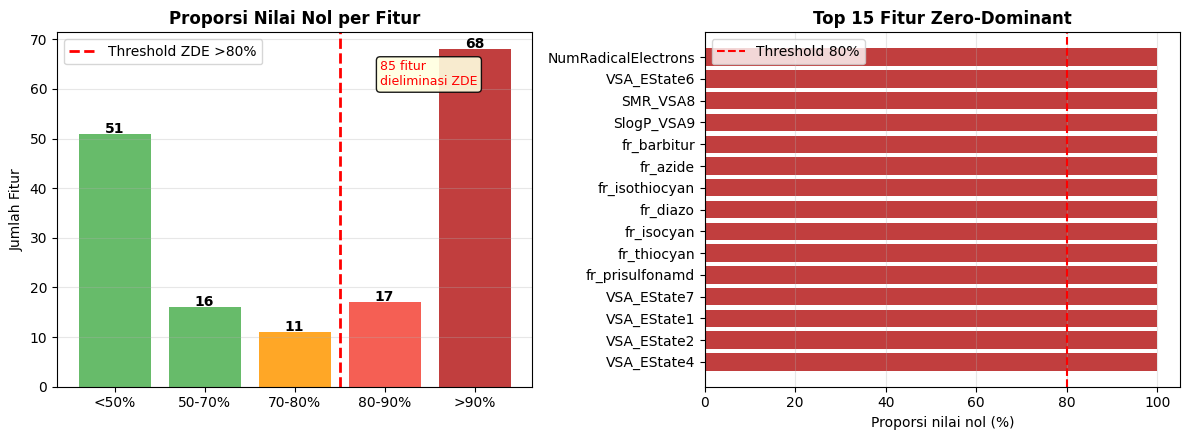

Fitur dieliminasi ZDE: 85 | Fitur tersisa: 111


In [17]:
zero_pct  = (X_eda == 0).mean()
zd_bins   = pd.cut(zero_pct, bins=[0,0.5,0.7,0.8,0.9,1.0],
                   labels=['<50%','50-70%','70-80%','80-90%','>90%'])
zd_counts = zd_bins.value_counts().sort_index()
n_zde     = int(sum(1 for c in X_eda.columns
                    if X_eda[c].value_counts(normalize=True).max() > 0.80))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
cols_z = ['#4CAF50','#4CAF50','#FF9800','#F44336','#B71C1C']
axes[0].bar(zd_counts.index, zd_counts.values, color=cols_z, alpha=0.85)
axes[0].axvline(2.5, color='red', lw=2, ls='--', label='Threshold ZDE >80%')
for bar, v in zip(axes[0].patches, zd_counts.values):
    axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.2, str(v),
                 ha='center', fontweight='bold')
axes[0].set_title('Proporsi Nilai Nol per Fitur', fontweight='bold')
axes[0].set_ylabel('Jumlah Fitur'); axes[0].legend(); axes[0].grid(axis='y', alpha=0.3)
axes[0].text(0.68, 0.85, f'{n_zde} fitur\ndieliminasi ZDE',
             transform=axes[0].transAxes, color='red', fontsize=9,
             bbox=dict(boxstyle='round', fc='lightyellow', alpha=0.9))

top15_z  = zero_pct.sort_values(ascending=False).head(15)
cols_top = ['#B71C1C' if v>0.90 else '#F44336' if v>0.80 else '#FF9800' for v in top15_z.values]
axes[1].barh(top15_z.index[::-1], top15_z.values[::-1]*100, color=cols_top[::-1], alpha=0.85)
axes[1].axvline(80, color='red', lw=1.5, ls='--', label='Threshold 80%')
axes[1].set_title('Top 15 Fitur Zero-Dominant', fontweight='bold')
axes[1].set_xlabel('Proporsi nilai nol (%)'); axes[1].legend(); axes[1].grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.show()
print(f'Fitur dieliminasi ZDE: {n_zde} | Fitur tersisa: {X_eda.shape[1]-n_zde}')

Spearman Correlation

Pasangan fitur berkorelasi > 0.85 : 217
Fitur unik yang terlibat           : 70

── Daftar semua pasangan berkorelasi tinggi ──
                Fitur_A                 Fitur_B  Korelasi
               fr_Ar_NH            fr_Nhpyrrole  1.000000
      MaxAbsEStateIndex          MaxEStateIndex  1.000000
 NumAromaticCarbocycles              fr_benzene  1.000000
             ExactMolWt                   MolWt  0.999982
                   Chi1          HeavyAtomCount  0.998408
         HeavyAtomMolWt                   MolWt  0.998054
             ExactMolWt          HeavyAtomMolWt  0.997923
                   Chi0          HeavyAtomCount  0.995835
                   Chi1                     Ipc  0.995822
                   Chi0     NumValenceElectrons  0.995387
         HeavyAtomCount               LabuteASA  0.995275
                   Chi1               LabuteASA  0.994492
         HeavyAtomCount     NumValenceElectrons  0.993302
         HeavyAtomCount                     Ipc  0.992855
  

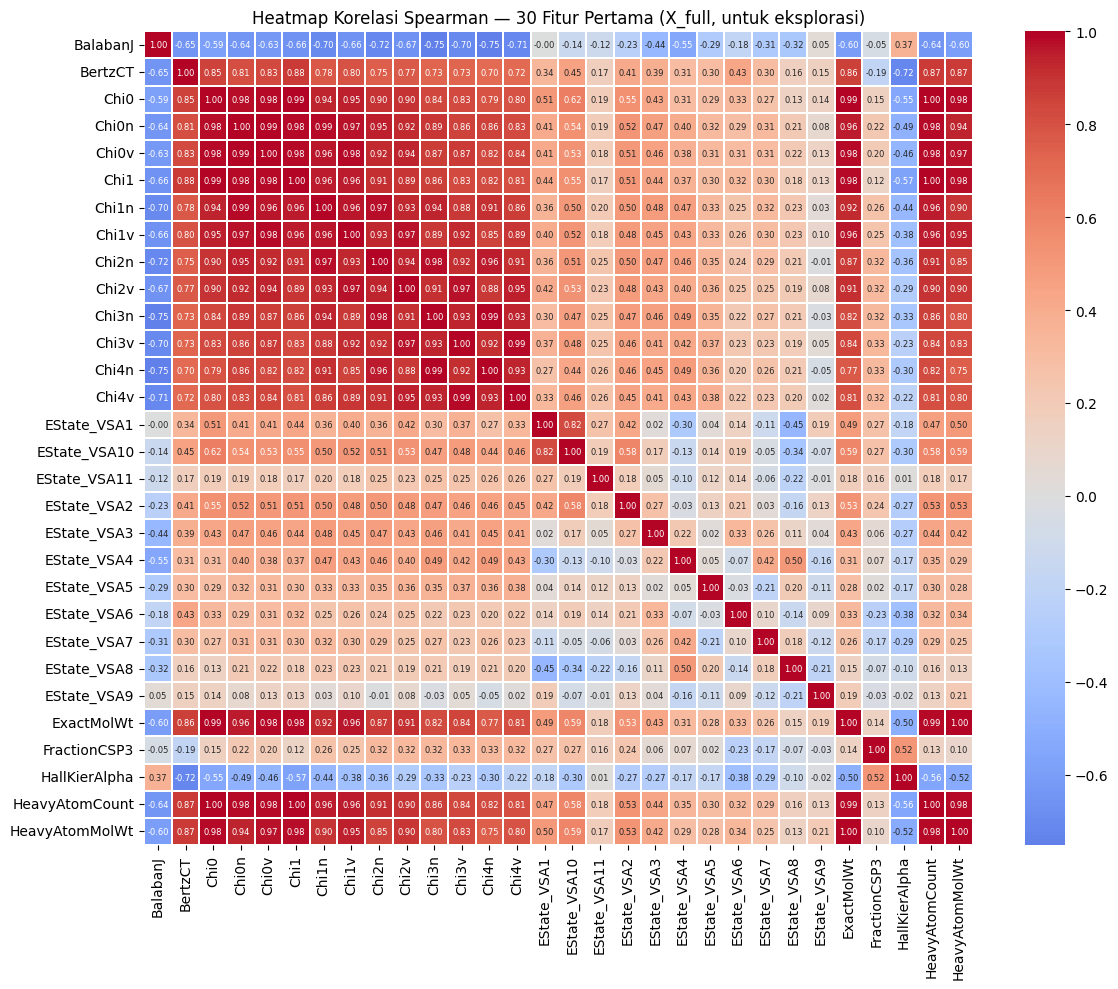

In [18]:
corr_matrix = X_full.corr(method='spearman')
upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

high_corr = (
    upper.stack()
    .reset_index()
    .rename(columns={'level_0': 'Fitur_A', 'level_1': 'Fitur_B', 0: 'Korelasi'})
)
high_corr = high_corr[abs(high_corr['Korelasi']) > 0.85].sort_values(
    'Korelasi', ascending=False
).reset_index(drop=True)

# Fitur unik yang terlibat korelasi tinggi
fitur_terlibat = pd.unique(high_corr[['Fitur_A', 'Fitur_B']].values.ravel())

print(f"Pasangan fitur berkorelasi > 0.85 : {len(high_corr)}")
print(f"Fitur unik yang terlibat           : {len(fitur_terlibat)}")

print(f"\n── Daftar semua pasangan berkorelasi tinggi ──")
print(high_corr.to_string(index=False))

print(f"\n── Fitur unik yang terlibat ──")
for f in sorted(fitur_terlibat):
    print(f"  {f}")

plt.figure(figsize=(12, 10))
sample_cols = X_full.columns[:30]
sns.heatmap(
    X_full[sample_cols].corr(method='spearman'),
    cmap='coolwarm', center=0, linewidths=0.3,
    annot=True, fmt='.2f', annot_kws={'size': 6}
)
plt.title("Heatmap Korelasi Spearman — 30 Fitur Pertama (X_full, untuk eksplorasi)")
plt.tight_layout()
plt.show()

Mutual Information

Fitur informatif  (MI > 0.01) : 107
Fitur tidak info  (MI ≤ 0.01) : 89

── Daftar fitur informatif (MI > 0.01) ──
                   Fitur  MI_Score
               SMR_VSA10  0.105188
     MinAbsPartialCharge  0.103707
        MaxPartialCharge  0.086202
             EState_VSA1  0.084961
                SMR_VSA5  0.084736
                    TPSA  0.078271
                SMR_VSA6  0.067938
             EState_VSA8  0.065713
                SMR_VSA3  0.061638
               RingCount  0.060045
        MinPartialCharge  0.058735
               PEOE_VSA9  0.057618
            EState_VSA10  0.057084
               LabuteASA  0.056681
               PEOE_VSA7  0.053634
          MinEStateIndex  0.053254
                   Chi4v  0.052610
              PEOE_VSA12  0.051014
              SlogP_VSA1  0.048690
     MaxAbsPartialCharge  0.047250
                   MolMR  0.045536
                fr_azide  0.045466
                    Chi0  0.045329
             EState_VSA4  0.044063
           

<Figure size 1000x600 with 0 Axes>

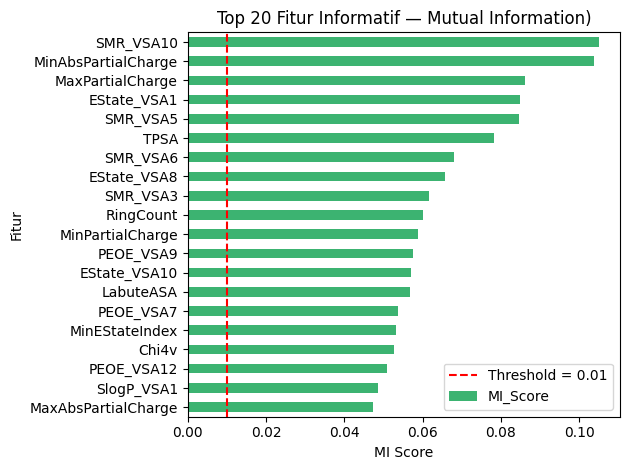

In [19]:
from sklearn.feature_selection import mutual_info_classif

# mi_scores_full: dipakai untuk EDA & ringkasan (eksplorasi dari X_full)
mi_scores_full = mutual_info_classif(X_full, y_full, random_state=42)
mi_df = pd.DataFrame({
    'Fitur'   : X_full.columns,
    'MI_Score': mi_scores_full
}).sort_values('MI_Score', ascending=False).reset_index(drop=True)

informative     = mi_df[mi_df['MI_Score'] >  0.01]
not_informative = mi_df[mi_df['MI_Score'] <= 0.01]

print(f"Fitur informatif  (MI > 0.01) : {len(informative)}")
print(f"Fitur tidak info  (MI ≤ 0.01) : {len(not_informative)}")

print(f"\n── Daftar fitur informatif (MI > 0.01) ──")
print(informative.to_string(index=False))

print(f"\n── Daftar fitur tidak informatif (MI ≤ 0.01) ──")
print(not_informative.to_string(index=False))

plt.figure(figsize=(10, 6))
mi_df.head(20).sort_values('MI_Score').plot(
    kind='barh', x='Fitur', y='MI_Score',
    color='mediumseagreen', legend=False
)
plt.axvline(0.01, color='red', linestyle='--', label='Threshold = 0.01')
plt.title("Top 20 Fitur Informatif — Mutual Information)")
plt.xlabel("MI Score")
plt.legend()
plt.tight_layout()
plt.show()


In [20]:
# ── RINGKASAN EKSPLORASI FITUR ───────────────────────────────────────────
summary = pd.DataFrame({
    'Variance'     : X_full.var(),
    'Zero_Pct'     : (X_full == 0).mean(),
    'Dominant_Pct' : X_full.apply(lambda c: c.value_counts(normalize=True).max()),
    'MI_Score'     : mi_scores_full
}, index=X_full.columns)

summary['Flag_LowVar'] = summary['Variance']      < 0.01   # VT
summary['Flag_ZDE']    = summary['Dominant_Pct']  > 0.80   # ZDE: nilai dominan, bukan hanya nol
summary['Flag_LowMI']  = summary['MI_Score']     <= 0.01   # MI

print("═" * 50)
print("       RINGKASAN EKSPLORASI FITUR (X_full)")
print("═" * 50)
print(f"  Total fitur                      : {len(summary)}")
print(f"  Low Variance  (< 0.01)           : {summary['Flag_LowVar'].sum()}")
print(f"  Zero-Dominant (nilai dom > 80%)  : {summary['Flag_ZDE'].sum()}")
print(f"  Low MI        (≤ 0.01)           : {summary['Flag_LowMI'].sum()}")
print(f"  Bermasalah (min 1 flag aktif)    : "
      f"{(summary[['Flag_LowVar','Flag_ZDE','Flag_LowMI']].any(axis=1)).sum()}")
print("═" * 50)

print(f"\n── Tabel lengkap semua fitur beserta nilai ──")
print(summary.to_string())

summary.to_csv('ringkasan_eksplorasi_fitur.csv')
print("\nDisimpan → ringkasan_eksplorasi_fitur.csv ✅")


══════════════════════════════════════════════════
       RINGKASAN EKSPLORASI FITUR (X_full)
══════════════════════════════════════════════════
  Total fitur                      : 196
  Low Variance  (< 0.01)           : 29
  Zero-Dominant (nilai dom > 80%)  : 84
  Low MI        (≤ 0.01)           : 89
  Bermasalah (min 1 flag aktif)    : 111
══════════════════════════════════════════════════

── Tabel lengkap semua fitur beserta nilai ──
                              Variance  Zero_Pct  Dominant_Pct  MI_Score  Flag_LowVar  Flag_ZDE  Flag_LowMI
BalabanJ                  5.245308e-01  0.000000      0.010050  0.037898        False     False       False
BertzCT                   1.634092e+05  0.000000      0.003350  0.035025        False     False       False
Chi0                      5.405493e+01  0.000000      0.010050  0.045329        False     False       False
Chi0n                     3.787080e+01  0.000000      0.003350  0.015325        False     False       False
Chi0v          

Jumlah Fitur tiap Teknik Seleksi

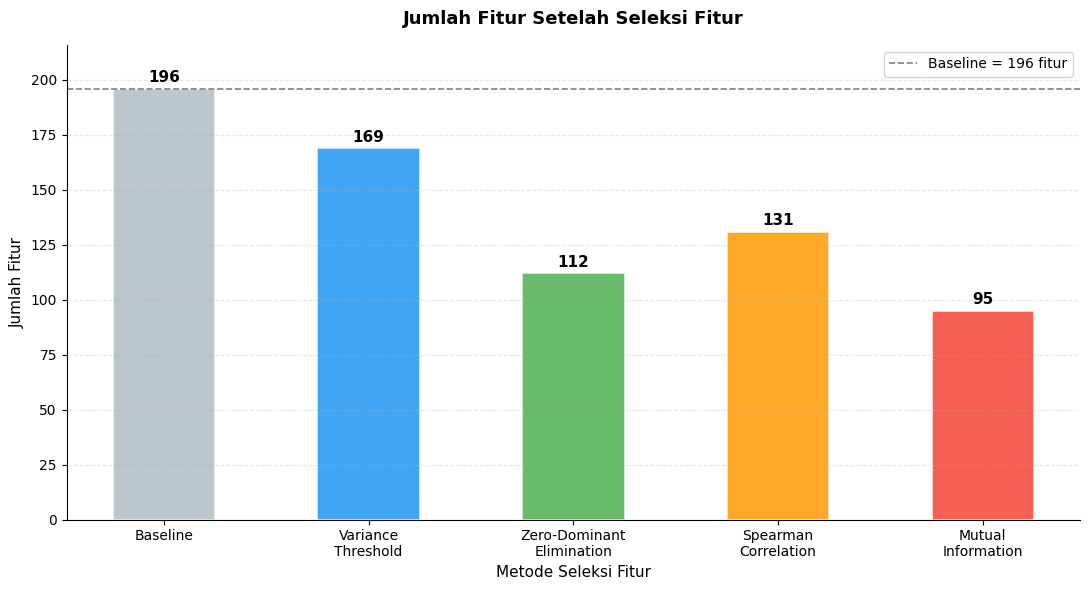

═════════════════════════════════════════════
   RINGKASAN JUMLAH FITUR HASIL SELEKSI
═════════════════════════════════════════════
  Metode                     Sisa  Buang
─────────────────────────────────────────────
  Baseline                    196      0
  Variance Threshold          169     27
  Zero-Dominant Elimination   112     84
  Spearman Correlation        131     65
  Mutual Information           95    101
═════════════════════════════════════════════


In [21]:
n_baseline = fs_8020['Baseline'][0].shape[1]
n_vt       = fs_8020['Variance Threshold'][0].shape[1]
n_zde      = fs_8020['Zero Dominant'][0].shape[1]
n_sp       = fs_8020['Spearman'][0].shape[1]
n_mi       = fs_8020['Mutual Information'][0].shape[1]

# ── DATA UNTUK CHART ──────────────────────────────────────────────────────
labels  = ['Baseline', 'Variance\nThreshold', 'Zero-Dominant\nElimination',
           'Spearman\nCorrelation', 'Mutual\nInformation']
n_fitur = [n_baseline, n_vt, n_zde, n_sp, n_mi]
colors  = ['#B0BEC5', '#2196F3', '#4CAF50', '#FF9800', '#F44336']

# ── PLOT ──────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.bar(labels, n_fitur, color=colors, width=0.5,
              edgecolor='white', linewidth=1.2, alpha=0.85)

for bar, val in zip(bars, n_fitur):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1.5,
        str(val),
        ha='center', va='bottom',
        fontsize=11, fontweight='bold'
    )

ax.axhline(y=n_baseline, color='gray', linestyle='--', linewidth=1.2,
           label=f'Baseline = {n_baseline} fitur')

ax.set_title("Jumlah Fitur Setelah Seleksi Fitur",
             fontsize=13, fontweight='bold', pad=15)
ax.set_ylabel("Jumlah Fitur", fontsize=11)
ax.set_xlabel("Metode Seleksi Fitur", fontsize=11)
ax.set_ylim(0, n_baseline + 20)
ax.legend(fontsize=10)
ax.grid(axis='y', linestyle='--', alpha=0.3)
sns.despine()

plt.tight_layout()
plt.show()

# ── PRINT RINGKASAN ───────────────────────────────────────────────────────
print("═" * 45)
print("   RINGKASAN JUMLAH FITUR HASIL SELEKSI") #(dihitung dari Xtr80 )
print("═" * 45)
print(f"  {'Metode':<26} {'Sisa':>4}  {'Buang':>5}")
print("─" * 45)
for label, n in zip(labels, n_fitur):
    label_clean = label.replace('\n', ' ')
    buang       = n_baseline - n
    print(f"  {label_clean:<26} {n:>4}  {buang:>5}")
print("═" * 45)


In [22]:
print(list(fs_8020.keys()))

['Baseline', 'Variance Threshold', 'Zero Dominant', 'Spearman', 'Mutual Information']


## 4. Konfigurasi Terbaik (dari NB01)

In [24]:
BEST_MODEL    = 'XGBoost'
BEST_FS       = 'Mutual Information'
BEST_SCENARIO = 'Full Data 80:20'

# fs_8020 sudah dibuat di cell preprocessing — tidak perlu buat ulang
fs_split = fs_8020
Xtr_mi, Xte_mi = fs_split[BEST_FS]

print(f'Model Terbaik  : {BEST_MODEL}')
print(f'Feature Select : {BEST_FS}')
print(f'Skenario       : {BEST_SCENARIO}')
print()
print('Jumlah fitur per metode FS (Xtr80):')
for name, (Xtr_i, _) in fs_split.items():
    marker = ' <- TERPILIH' if name == BEST_FS else ''
    print(f'  {name:<22}: {Xtr_i.shape[1]} fitur{marker}')


Model Terbaik  : XGBoost
Feature Select : Mutual Information
Skenario       : Full Data 80:20

Jumlah fitur per metode FS (Xtr80):
  Baseline              : 196 fitur
  Variance Threshold    : 169 fitur
  Zero Dominant         : 112 fitur
  Spearman              : 131 fitur
  Mutual Information    : 95 fitur <- TERPILIH


## 5. HP Tuning — GridSearchCV via `tune_model`


In [25]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from xgboost import XGBClassifier

print('Menjalankan GridSearchCV HP Tuning...')
print(f'  Search space XGB : {len(list(__import__("itertools").product(*PARAM_GRID_XGB.values())))} kombinasi')
print(f'  Inner CV         : StratifiedKFold(n_splits=3)')
print(f'  Scoring          : matthews_corrcoef')
print()

final_model = tune_model(
    model_name = BEST_MODEL,
    X          = Xtr_mi,
    y          = ytr80_r
)

print('HP Tuning selesai.')
print(f'Best params: {final_model.get_params()}')


Menjalankan GridSearchCV HP Tuning...
  Search space XGB : 108 kombinasi
  Inner CV         : StratifiedKFold(n_splits=3)
  Scoring          : matthews_corrcoef

HP Tuning selesai.
Best params: {'objective': 'binary:logistic', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': 1.0, 'device': None, 'early_stopping_rounds': None, 'enable_categorical': False, 'eval_metric': 'logloss', 'feature_types': None, 'feature_weights': None, 'gamma': None, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': 0.3, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'max_depth': 9, 'max_leaves': None, 'min_child_weight': None, 'missing': nan, 'monotone_constraints': None, 'multi_strategy': None, 'n_estimators': 200, 'n_jobs': None, 'num_parallel_tree': None, 'random_state': 42, 'reg_alpha': None, 'reg_lambda': None, 'sampling_method': None

## 6. Evaluasi Final — Holdout 80:20

In [26]:
y_pred_test  = final_model.predict(Xte_mi)
y_proba_test = final_model.predict_proba(Xte_mi)[:, 1]
y_pred_train = final_model.predict(Xtr_mi)

res       = evaluate(yte80_r, y_pred_test, y_proba_test)
train_acc = accuracy_score(ytr80_r, y_pred_train)
test_acc  = accuracy_score(yte80_r, y_pred_test)
train_f1  = f1_score(ytr80_r, y_pred_train, average='macro', zero_division=0)
test_f1   = f1_score(yte80_r, y_pred_test,  average='macro', zero_division=0)

print('=' * 65)
print(f'  {BEST_MODEL} + {BEST_FS} | {BEST_SCENARIO}')
print('-' * 65)
for m_name, v in res.items():
    print(f'  {m_name:<14}: {v:.4f}')
print('-' * 65)
print(f'  Train Accuracy : {train_acc:.4f} | Test Accuracy : {test_acc:.4f}')
print(f'  Gap Accuracy   : {train_acc - test_acc:.4f}')
print(f'  Train Macro F1 : {train_f1:.4f} | Test Macro F1 : {test_f1:.4f}')
print(f'  Gap Macro F1   : {train_f1 - test_f1:.4f}')
print('=' * 65)
print()


  XGBoost + Mutual Information | Full Data 80:20
-----------------------------------------------------------------
  Accuracy      : 0.8583
  Precision     : 0.8126
  Recall        : 0.8056
  F1-Score      : 0.8090
  MCC           : 0.6181
  ROC-AUC       : 0.8967
-----------------------------------------------------------------
  Train Accuracy : 0.9979 | Test Accuracy : 0.8583
  Gap Accuracy   : 0.1396
  Train Macro F1 : 0.9972 | Test Macro F1 : 0.8090
  Gap Macro F1   : 0.1882



## 7. Confusion Matrix

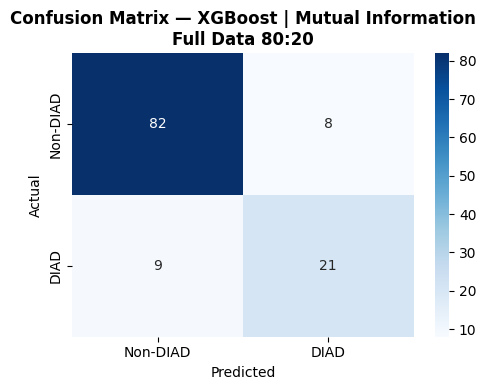

              precision    recall  f1-score   support

    Non-DIAD       0.90      0.91      0.91        90
        DIAD       0.72      0.70      0.71        30

    accuracy                           0.86       120
   macro avg       0.81      0.81      0.81       120
weighted avg       0.86      0.86      0.86       120



In [27]:
cm = confusion_matrix(yte80_r, y_pred_test)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Non-DIAD','DIAD'],
            yticklabels=['Non-DIAD','DIAD'])
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.title(f'Confusion Matrix — {BEST_MODEL} | {BEST_FS}\n{BEST_SCENARIO}', fontweight='bold')
plt.tight_layout(); plt.show()

print(classification_report(yte80_r, y_pred_test, target_names=['Non-DIAD','DIAD']))

## 8. SHAP — Feature Importance

In [28]:
sv, Xsv = compute_shap(final_model, Xtr_mi, BEST_MODEL)
print(f'SHAP selesai. sv: {sv.shape} | Fitur: {Xtr_mi.shape[1]}')


sv shape : (477, 95) | Xsv shape: (477, 95)
SHAP selesai. sv: (477, 95) | Fitur: 95


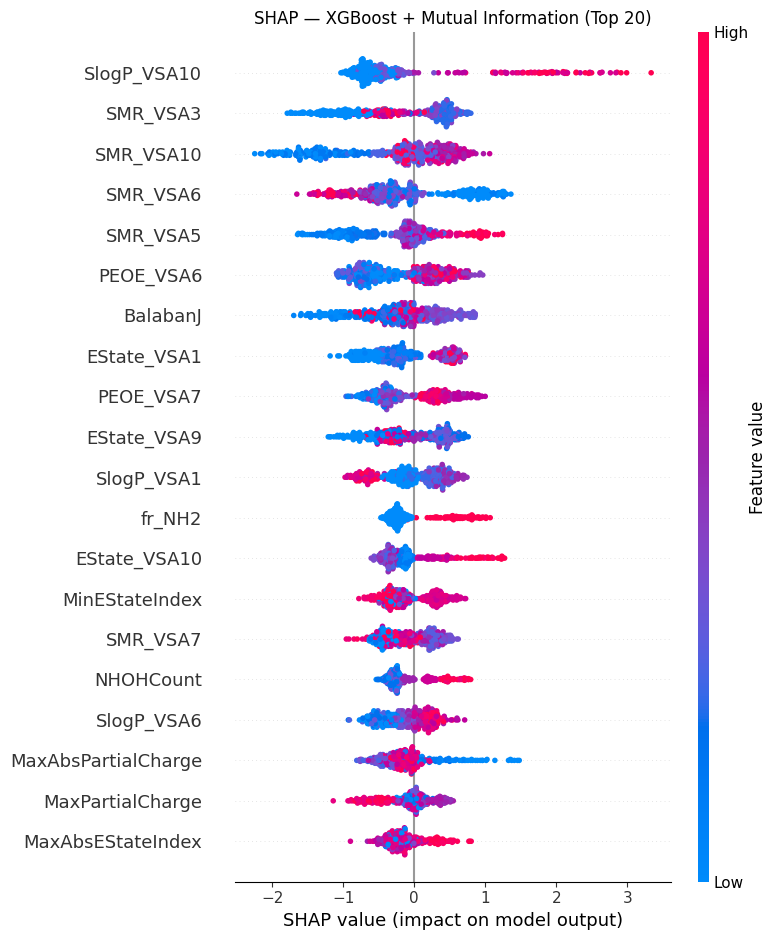

  -> shap_beeswarm.png


In [29]:
plot_shap_beeswarm(sv, Xsv, BEST_MODEL, BEST_FS, save_path='shap_beeswarm.png')

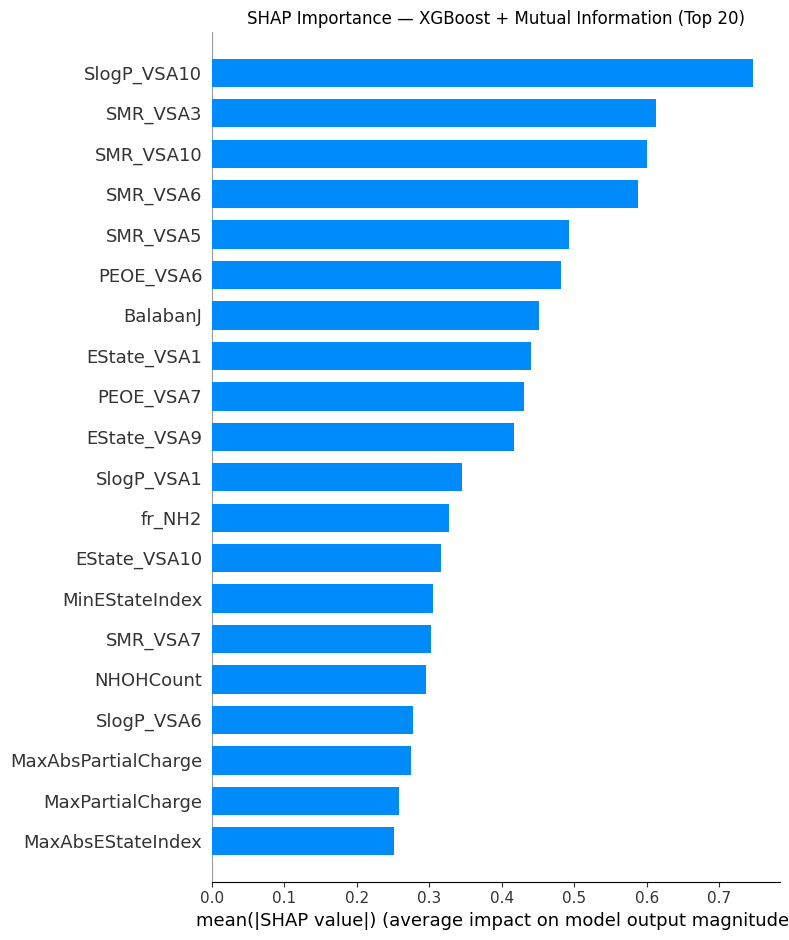

  -> shap_bar.png


In [30]:
plot_shap_bar(sv, Xsv, BEST_MODEL, BEST_FS, save_path='shap_bar.png')

In [31]:
shap_table = (pd.DataFrame({
                  'Feature'    : Xsv.columns,
                  'Mean |SHAP|': np.abs(sv).mean(axis=0)
              })
              .sort_values('Mean |SHAP|', ascending=False)
              .reset_index(drop=True))
shap_table.index      = shap_table.index + 1
shap_table.index.name = 'Rank'
shap_table['Mean |SHAP|'] = shap_table['Mean |SHAP|'].round(4)
print(f'Feature Importance — {BEST_MODEL} + {BEST_FS} (Top 20)')
print('=' * 42)
print(shap_table.head(20).to_string())

Feature Importance — XGBoost + Mutual Information (Top 20)
                  Feature  Mean |SHAP|
Rank                                  
1             SlogP_VSA10       0.7466
2                SMR_VSA3       0.6124
3               SMR_VSA10       0.5998
4                SMR_VSA6       0.5884
5                SMR_VSA5       0.4931
6               PEOE_VSA6       0.4812
7                BalabanJ       0.4509
8             EState_VSA1       0.4399
9               PEOE_VSA7       0.4312
10            EState_VSA9       0.4166
11             SlogP_VSA1       0.3451
12                 fr_NH2       0.3264
13           EState_VSA10       0.3154
14         MinEStateIndex       0.3048
15               SMR_VSA7       0.3021
16              NHOHCount       0.2956
17             SlogP_VSA6       0.2775
18    MaxAbsPartialCharge       0.2745
19       MaxPartialCharge       0.2575
20      MaxAbsEStateIndex       0.2508


## 9. Ekspor Hasil

In [32]:
pd.DataFrame([{'Model': BEST_MODEL, 'Feature Selection': BEST_FS,
               'Skenario': BEST_SCENARIO,
               'Train Accuracy': train_acc, 'Test Accuracy': test_acc,
               'Gap Accuracy': train_acc - test_acc,
               'Train Macro F1': train_f1, 'Test Macro F1': test_f1,
               'Gap Macro F1': train_f1 - test_f1,
               **res}]
).to_csv('model_terbaik_final.csv', index=False)

shap_table.to_csv('shap_feature_importance.csv')
print('File tersimpan:')
print('  model_terbaik_final.csv')
print('  shap_feature_importance.csv')
print('  shap_beeswarm.png')
print('  shap_bar.png')
print()
print('=' * 55)
print(f'  MODEL AKHIR  : {BEST_MODEL}')
print(f'  FEATURE SET  : {BEST_FS}')
print(f'  SKENARIO     : {BEST_SCENARIO}')
print('-' * 55)
for m_name, v in res.items():
    print(f'  {m_name:<12}: {v:.4f}')
print('=' * 55)

File tersimpan:
  model_terbaik_final.csv
  shap_feature_importance.csv
  shap_beeswarm.png
  shap_bar.png

  MODEL AKHIR  : XGBoost
  FEATURE SET  : Mutual Information
  SKENARIO     : Full Data 80:20
-------------------------------------------------------
  Accuracy    : 0.8583
  Precision   : 0.8126
  Recall      : 0.8056
  F1-Score    : 0.8090
  MCC         : 0.6181
  ROC-AUC     : 0.8967


In [33]:
# ══════════════════════════════════════════════════════════════
#  CELL EKSPOR NB02 — Simpan semua untuk Streamlit app
#  Feature Selection: Mutual Information (MI)
# ══════════════════════════════════════════════════════════════
import pickle, os
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (
    accuracy_score, f1_score, matthews_corrcoef, roc_auc_score
)

os.makedirs("model", exist_ok=True)

# ── 1. Rekonstruksi scaler dari Xtr80 raw (sebelum scaling) ──────────────
#    make_feature_sets_split: sc.fit_transform(Xtr_raw) pada 196 fitur
Xtr80_raw = Xtr80.reset_index(drop=True)

sc_export = StandardScaler()
sc_export.fit(Xtr80_raw)
print(f"✅ Scaler fit pada {Xtr80_raw.shape[0]} sampel x {Xtr80_raw.shape[1]} fitur")

# ── 2. Rekonstruksi daftar fitur MI dari Xtr80 (identik make_feature_sets_split) ─
#    Langkah: scale Xtr80 → hitung MI → pilih MI > 0.01
Xtr80_scaled     = sc_export.transform(Xtr80_raw)
mi_scores_export = mutual_info_classif(Xtr80_scaled, ytr80_r, random_state=42)
mi_mask_export   = mi_scores_export > 0.01
mi_cols_export   = Xtr80_raw.columns[mi_mask_export].tolist()

print(f"✅ MI: {len(mi_cols_export)} fitur terpilih (dari {Xtr80_raw.shape[1]} fitur asli)")

# ── 3. Verifikasi konsistensi dengan Xtr_mi dari pipeline ────────────────
selected_features_export = Xtr_mi.columns.tolist()
assert set(selected_features_export) == set(mi_cols_export), (
    f"PERINGATAN: Fitur tidak konsisten!\n"
    f"  Pipeline MI : {len(selected_features_export)} fitur\n"
    f"  Rekonstruksi: {len(mi_cols_export)} fitur"
)
print(f"✅ Konsistensi fitur MI terverifikasi: {len(selected_features_export)} fitur")

# ── 4. Simpan model final ─────────────────────────────────────────────────
with open("model/xgb_model.pkl", "wb") as f:
    pickle.dump(final_model, f)
print("✅ xgb_model.pkl tersimpan")

# ── 5. Simpan selected_features (daftar nama kolom MI) ───────────────────
with open("model/selected_features.pkl", "wb") as f:
    pickle.dump(selected_features_export, f)
print("✅ selected_features.pkl tersimpan")

# ── 6. Simpan scaler (fit pada 196 fitur asli) ───────────────────────────
with open("model/scaler.pkl", "wb") as f:
    pickle.dump(sc_export, f)
print("✅ scaler.pkl tersimpan")

# ── 7. Hitung & simpan metrik dari evaluasi holdout ──────────────────────
y_pred_export = final_model.predict(Xte_mi)
y_prob_export = final_model.predict_proba(Xte_mi)[:, 1]

metrics_export = {
    "_version"   : "v10_xgb_mi_8020_holdout",
    "accuracy"   : float(accuracy_score(yte80_r, y_pred_export)),
    "mcc"        : float(matthews_corrcoef(yte80_r, y_pred_export)),
    "f1"         : float(f1_score(yte80_r, y_pred_export,
                                  average="macro", zero_division=0)),
    "roc_auc"    : float(roc_auc_score(yte80_r, y_prob_export)),
    "skenario"   : "Full Data 80:20 Holdout",
    "fs_method"  : "Mutual Information",
    "n_fitur_mi" : len(selected_features_export),
    "n_fitur_raw": Xtr80_raw.shape[1],
}
with open("model/model_metrics.pkl", "wb") as f:
    pickle.dump(metrics_export, f)
print(f"✅ model_metrics.pkl tersimpan")
print(f"   MCC     = {metrics_export['mcc']:.4f}")
print(f"   ROC-AUC = {metrics_export['roc_auc']:.4f}")
print(f"   Akurasi = {metrics_export['accuracy']*100:.2f}%")
print(f"   Fitur MI: {metrics_export['n_fitur_mi']} / {metrics_export['n_fitur_raw']}")

# ── 8. Simpan SHAP values ─────────────────────────────────────────────────
shap_export = {
    "sv"     : np.array(sv,  dtype=float),
    "Xsv"    : Xsv.reset_index(drop=True),
    "version": "from_notebook"
}
with open("model/shap_values.pkl", "wb") as f:
    pickle.dump(shap_export, f)
print(f"✅ shap_values.pkl tersimpan")
print(f"   sv shape : {shap_export['sv'].shape}")
print(f"   Xsv shape: {shap_export['Xsv'].shape}")

# ── Ringkasan akhir ───────────────────────────────────────────────────────
print("\n" + "═"*52)
print("   EKSPOR SELESAI — File siap untuk Streamlit")
print("   Feature Selection : Mutual Information")
print("═"*52)
artifacts = [
    "xgb_model.pkl", "selected_features.pkl",
    "scaler.pkl", "model_metrics.pkl", "shap_values.pkl"
]
for fname in artifacts:
    path = f"model/{fname}"
    size = os.path.getsize(path) / 1024
    print(f"  ✅ {fname:<28} ({size:.1f} KB)")

print()
print("  Alur prediksi Streamlit:")
print("  input (196 fitur) → scaler → pilih selected_features → xgb_model → output")


✅ Scaler fit pada 477 sampel x 196 fitur
✅ MI: 95 fitur terpilih (dari 196 fitur asli)
✅ Konsistensi fitur MI terverifikasi: 95 fitur
✅ xgb_model.pkl tersimpan
✅ selected_features.pkl tersimpan
✅ scaler.pkl tersimpan
✅ model_metrics.pkl tersimpan
   MCC     = 0.6181
   ROC-AUC = 0.8967
   Akurasi = 85.83%
   Fitur MI: 95 / 196
✅ shap_values.pkl tersimpan
   sv shape : (477, 95)
   Xsv shape: (477, 95)

════════════════════════════════════════════════════
   EKSPOR SELESAI — File siap untuk Streamlit
   Feature Selection : Mutual Information
════════════════════════════════════════════════════
  ✅ xgb_model.pkl                (218.8 KB)
  ✅ selected_features.pkl        (1.2 KB)
  ✅ scaler.pkl                   (7.7 KB)
  ✅ model_metrics.pkl            (0.2 KB)
  ✅ shap_values.pkl              (710.6 KB)

  Alur prediksi Streamlit:
  input (196 fitur) → scaler → pilih selected_features → xgb_model → output


In [ ]:
import pickle

with open("model/selected_features.pkl", "rb") as f:
    selected_features = pickle.load(f)

print("Jumlah fitur MI:", len(selected_features))

Jumlah fitur MI: 95


In [36]:
len(selected_features)

95

In [4]:
import pickle

model = pickle.load(open("../model/xgb_model.pkl", "rb"))
params = model.get_params()
for k, v in params.items():
    if v is not None:
        print(f"{k:30s}: {v}")

objective                     : binary:logistic
colsample_bytree              : 1.0
enable_categorical            : False
eval_metric                   : logloss
learning_rate                 : 0.3
max_depth                     : 9
missing                       : nan
n_estimators                  : 200
random_state                  : 42
scale_pos_weight              : 3.042372881355932
subsample                     : 0.7
verbosity                     : 0
